# Theoretical SCD Gallery

The second-order cycle frequencies of every signal in `scf_test.signals`, estimated and compared with theory.

Each signal is long and nearly noise-free, so the features stand well clear of the floor. The SCD is estimated
with the FAM (Hamming windows for both $a(n)$ and $g(n)$), and its spectral coherence (the SCD over the Welch PSD)
gives the cyclic domain profile $I(\alpha) = \max_f |C_x^\alpha(f)|$. The coherence puts every feature on the
same scale, whatever the signal power and the PSD at $f \pm \alpha/2$.

No threshold theory is needed for peaks this prominent: a peak is any local maximum of the profile above
`FACTOR` times its median, keeping the highest within $1/N_p$ (the cycle leakage around each feature).

For each signal, the left column shows the profile (non-conjugate on top, conjugate below) with:
- the cycle frequencies from theory (green);
- the threshold (dashed orange);
- the peaks found (red).

The right column shows the SCD slices $|S_x^\alpha(f)|$ at those peaks, with the PSD ($\alpha = 0$) added to the
non-conjugate slices. The non-conjugate SCD is symmetric in $\alpha$, so only $\alpha > 0$ is shown.

**Note:** the 3D plots draw at most `MAX_SLICES` = 12 slices, those of the 12 highest peaks, so that signals with many
features (e.g. 19 conjugate features for rectangular BPSK, ASK and OOK, 59 for 2FSK) stay readable. The CDP on the
left shows every peak found. The slices are on a linear scale, so features far from $\alpha = 0$ can look nearly
flat. With a rectangular pulse, for example, $f \pm \alpha/2$ falls in the sidelobes of the spectrum, where the SCD is
small, even though the coherence there is close to 1.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

from scf_test import fam, psd, spectral_correlation_to_coherence
from scf_test.tests import compute_cdp
from scf_test.signals import SIGNALS, make_signal, expected_cycle_frequencies, SAMPLES_PER_SYMBOL
from scf_test.visualization.scd import plot_slices_3d

N = 2**17          # samples (13107 symbols at 10 samples per symbol)
SNR = 20           # dB
NP = 128           # FAM channels; frequency resolution 1/NP
L = NP // 4        # FAM hop
FACTOR = 4         # peak threshold, in multiples of the median of the profile
TOLERANCE = 1e-3   # a peak this close to a cycle frequency from theory matches it
MAX_SLICES = 12    # slices drawn in 3D: the strongest peaks, so that signals with many features stay readable
rng = np.random.default_rng(2026)

print(f"N = {N} ({N // SAMPLES_PER_SYMBOL} symbols), SNR = {SNR} dB, Np = {NP}, L = {L}")

N = 131072 (13107 symbols), SNR = 20 dB, Np = 128, L = 32


In [2]:
def estimate(x, conjugate):
    # FAM SCD (Hamming a(n) and g(n)), and its coherence: the same as fam(..., coherence=True), without a second run
    Sx, f, alpha = fam(x, Np=NP, L=L, conjugate=conjugate)
    coherence = spectral_correlation_to_coherence(psd(x, L=NP, method="welch"), Sx, f, alpha, conjugate=conjugate)
    return Sx, coherence, f, alpha


def prominent_peaks(cf, cdp, conjugate):
    # Leave out the edges of the FAM's support and, for the non-conjugate SCD, alpha <= 0
    # (alpha = 0 has a coherence of 1 and leaks into its neighbours; alpha < 0 mirrors alpha > 0)
    guard = np.abs(cf) > 1 - 1 / NP
    if not conjugate:
        guard |= cf < 2 / NP
    level = FACTOR * np.median(cdp[~guard])
    peaks, _ = find_peaks(np.where(guard, 0, cdp), height=level, distance=N // NP)
    return cf[peaks], cdp[peaks], level, guard


def compare(found, expected):
    matched = [e for e in expected if np.any(np.abs(found - e) < TOLERANCE)]
    missing = [e for e in expected if e not in matched]
    extra = [p for p in found if not np.any(np.abs(expected - p) < TOLERANCE)]
    return matched, missing, extra


def show(name):
    x, _ = make_signal(name, N, snr=SNR, rng=rng)
    fig = plt.figure(figsize=(13, 7.2))
    fig.suptitle(SIGNALS[name].label, fontsize=13)
    spec = fig.add_gridspec(2, 2, width_ratios=[1, 1.1])
    summary = {"signal": SIGNALS[name].label}

    for row, conjugate in enumerate((False, True)):
        kind = "conjugate" if conjugate else "non-conjugate"
        Sx, coherence, f, alpha = estimate(x, conjugate)
        cf, cdp = compute_cdp(coherence, alpha)
        peaks, heights, level, guard = prominent_peaks(cf, cdp, conjugate)
        expected = expected_cycle_frequencies(name, conjugate)
        matched, missing, extra = compare(peaks, expected)
        summary |= {f"{kind} theory": len(expected), f"{kind} found": len(matched),
                    f"{kind} missing": ", ".join(f"{m:.3g}" for m in missing),
                    f"{kind} extra": ", ".join(f"{e:.4g}" for e in extra)}

        ax = fig.add_subplot(spec[row, 0])
        shown = cf >= 0 if not conjugate else np.ones(len(cf), bool)
        for e in expected:
            ax.axvline(e, color="tab:green", linewidth=1.5, alpha=0.35, zorder=0)
        ax.plot(cf[shown], cdp[shown], color="0.25", linewidth=0.5)
        ax.axhline(level, color="tab:orange", linewidth=0.8, linestyle="--")
        ax.plot(peaks, heights, "o", color="tab:red", ms=4, mfc="none")
        ax.set_xlim(0 if not conjugate else -1, 1)
        ax.set_ylim(0, 1.15 * np.max(cdp[~guard]))
        ax.set_xlabel(r"Cycle frequency $\alpha$")
        ax.set_ylabel(r"max$_f$ |C|")
        ax.set_title(f"{kind.capitalize()} coherence CDP: {len(matched)}/{len(expected)} from theory found"
                     + (f", {len(extra)} extra" if extra else ""), fontsize=9)
        ax.grid(True, alpha=0.3)

        ax3d = fig.add_subplot(spec[row, 1], projection="3d")
        strongest = sorted(peaks[np.argsort(heights)[::-1][:MAX_SLICES]])
        slices = sorted(strongest + ([0.0] if not conjugate else []))
        if slices:
            plot_slices_3d(Sx, f, alpha, slices, ax3d)
            ax3d.set_box_aspect(None, zoom=1.2)
            shown_as = ", ".join(f"{a:.3g}" for a in slices)
            if len(peaks) > MAX_SLICES:
                shown_as = f"the {MAX_SLICES} strongest of {len(peaks)} peaks" + (" and 0" if not conjugate else "")
            ax3d.set_title(rf"SCD slices at $\alpha$ = {shown_as}", fontsize=8)
        else:
            ax3d.set_axis_off()
            ax3d.text2D(0.5, 0.5, f"No {kind} features", ha="center", va="center", transform=ax3d.transAxes)

    fig.tight_layout()
    plt.show()
    return summary

## Gallery

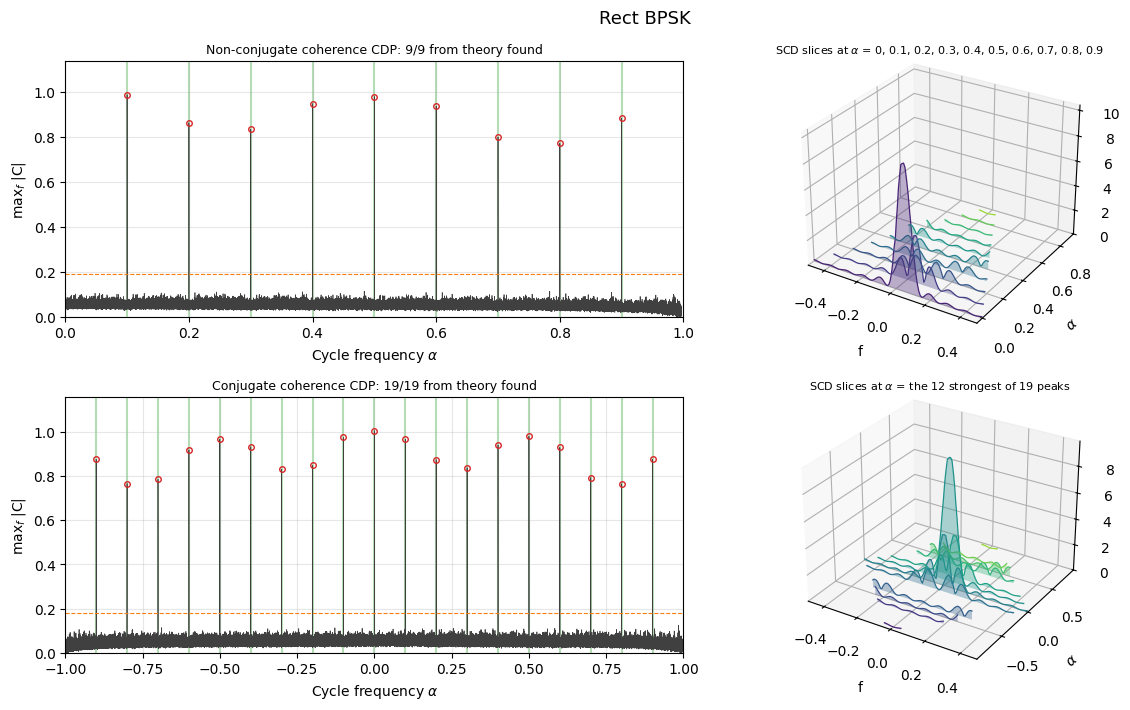

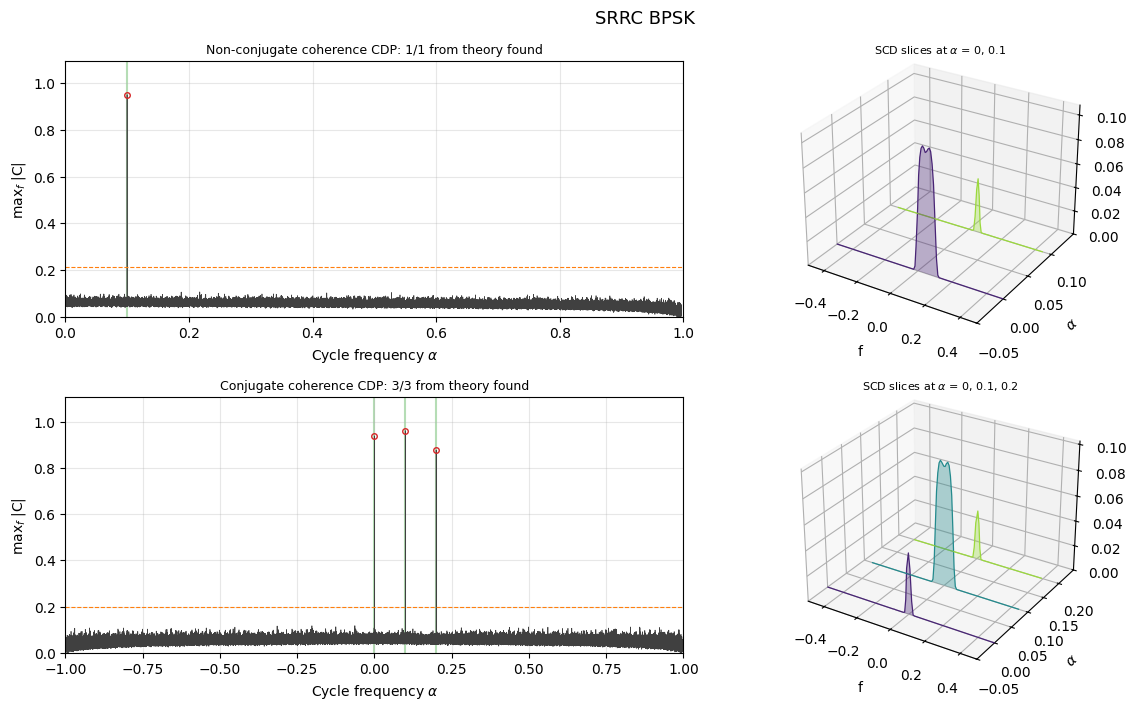

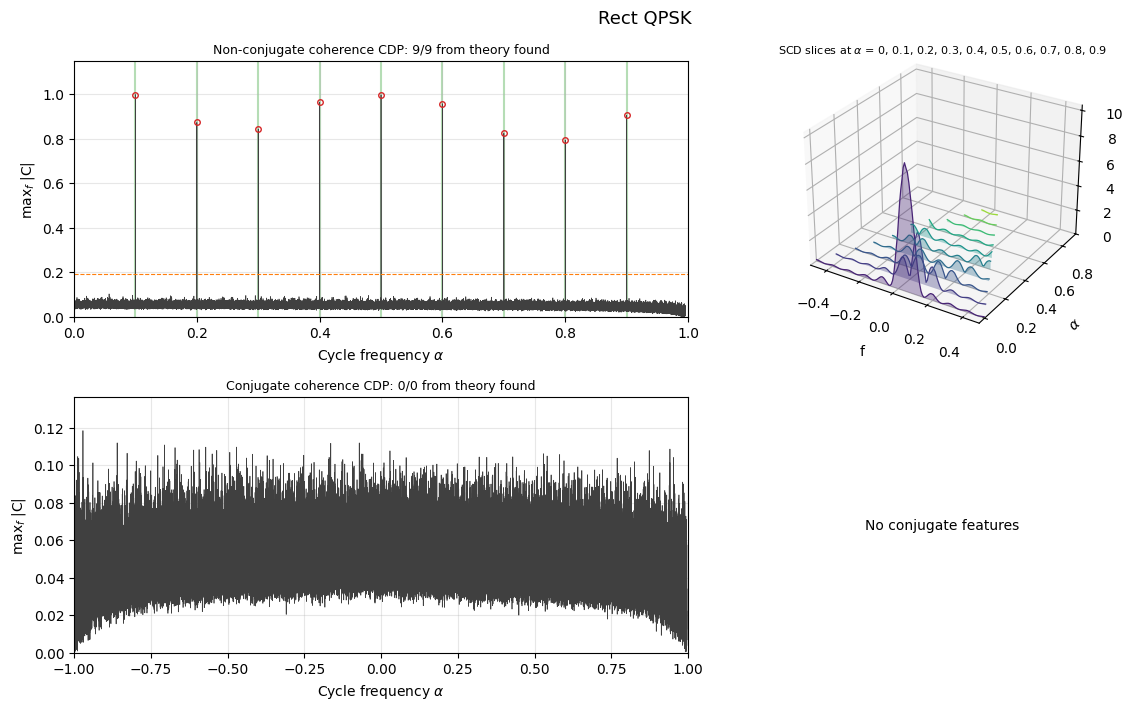

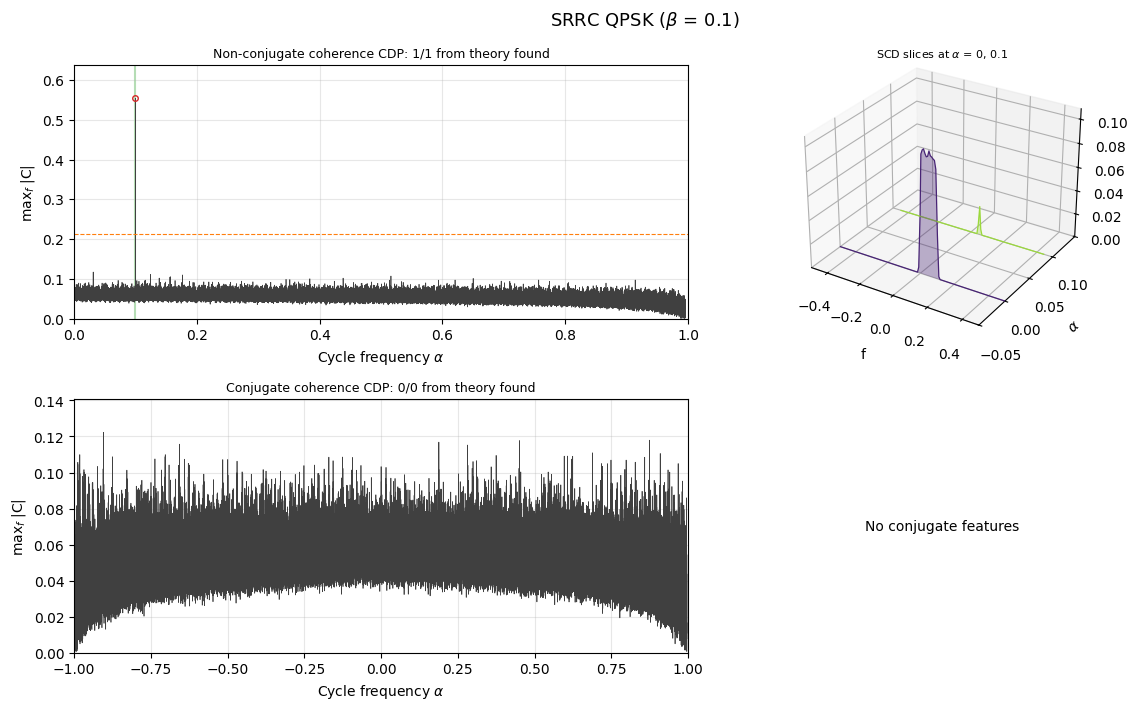

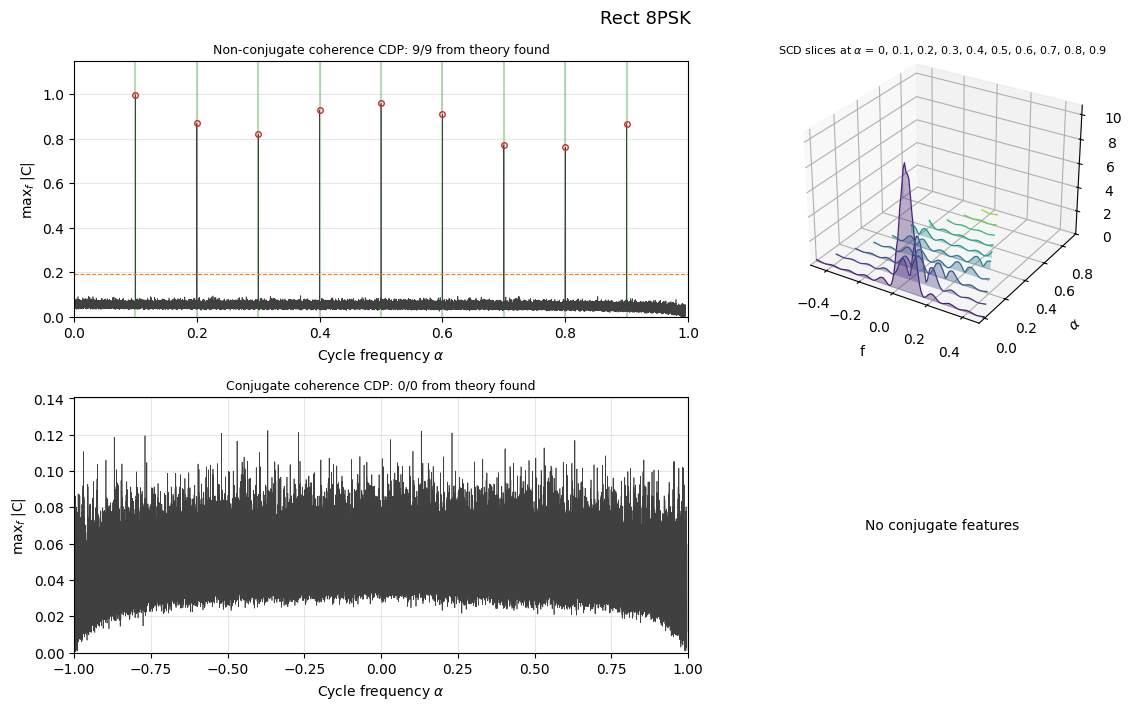

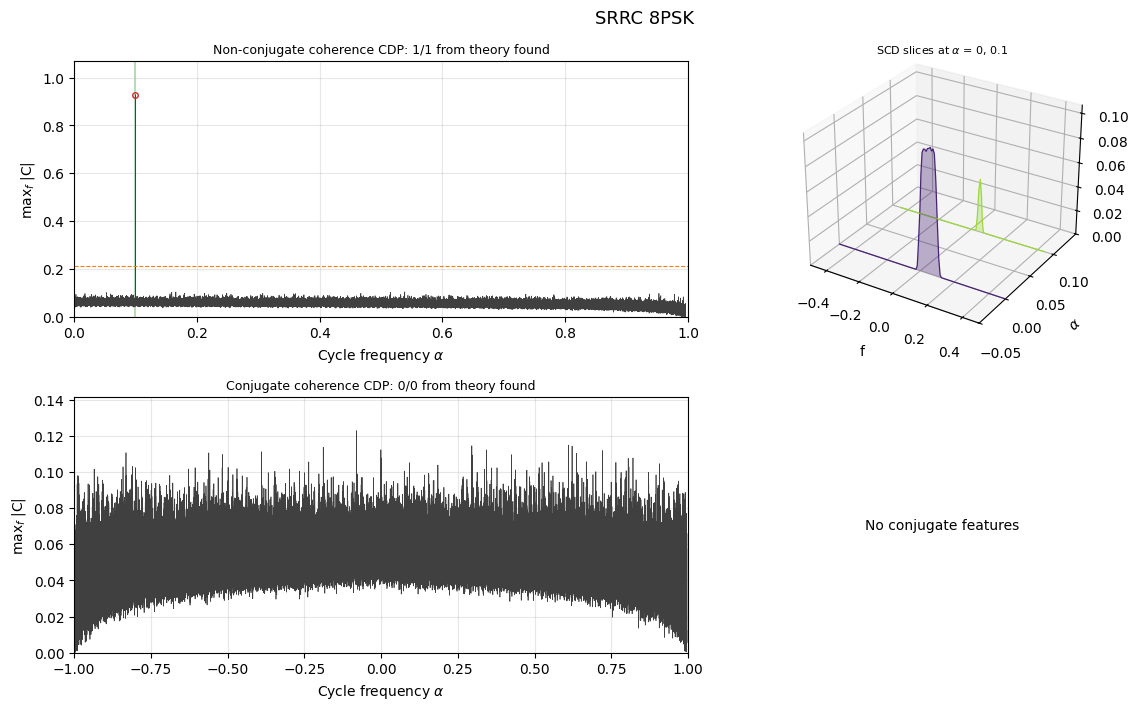

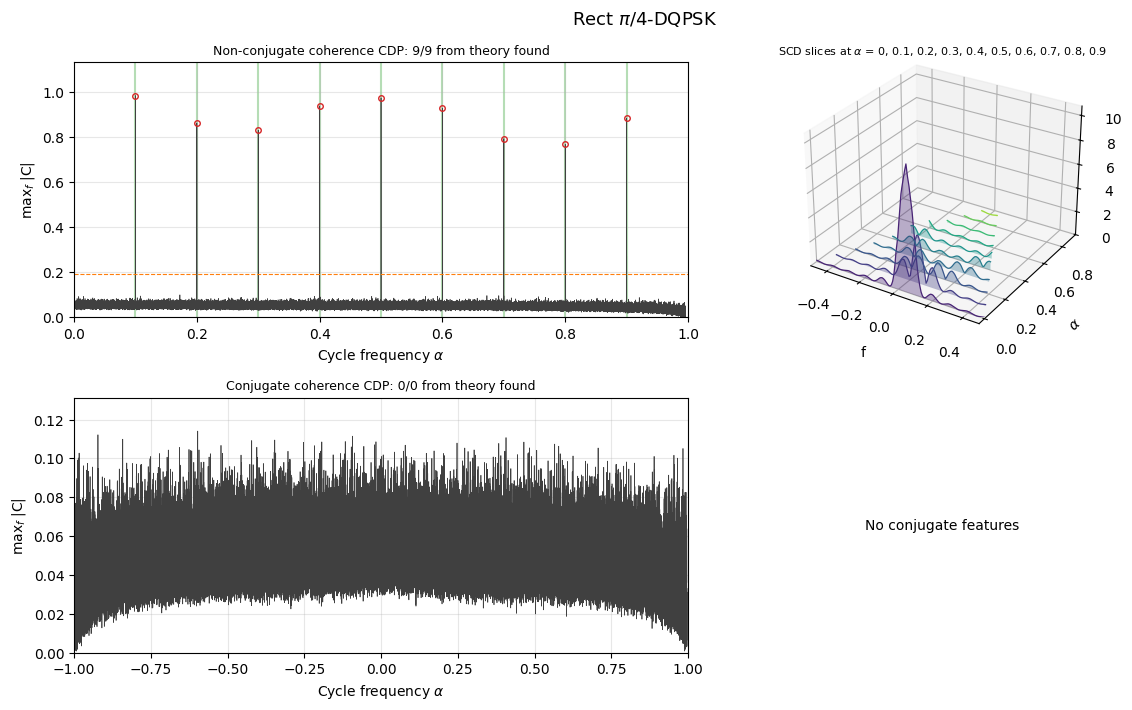

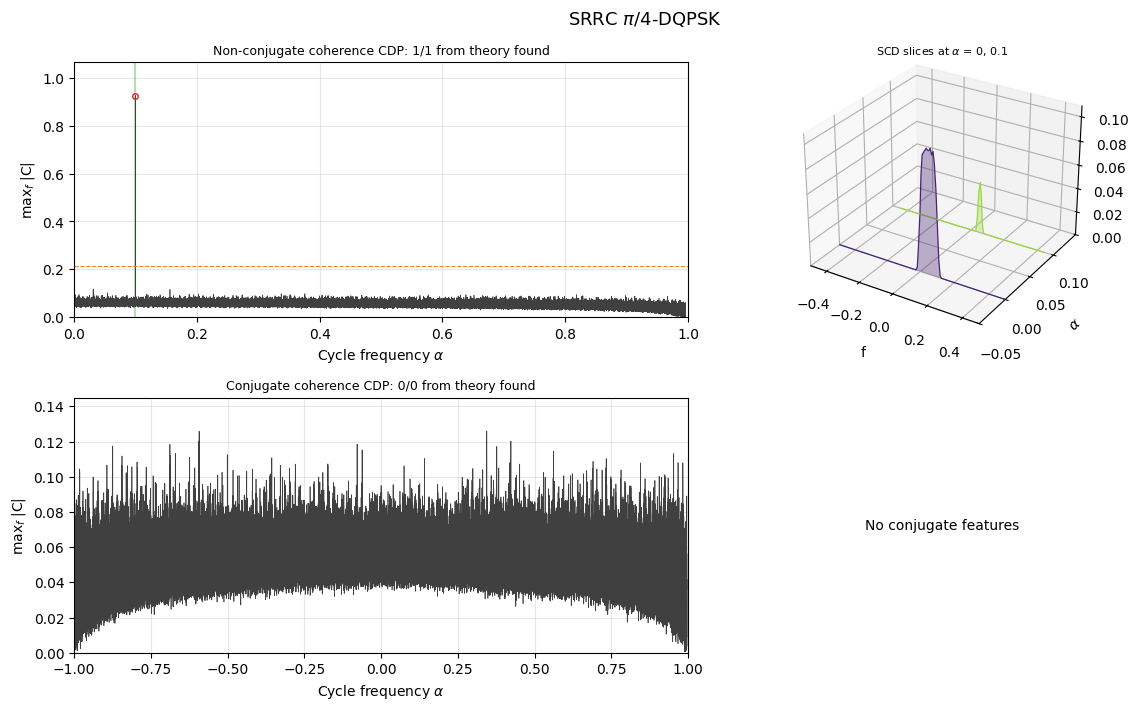

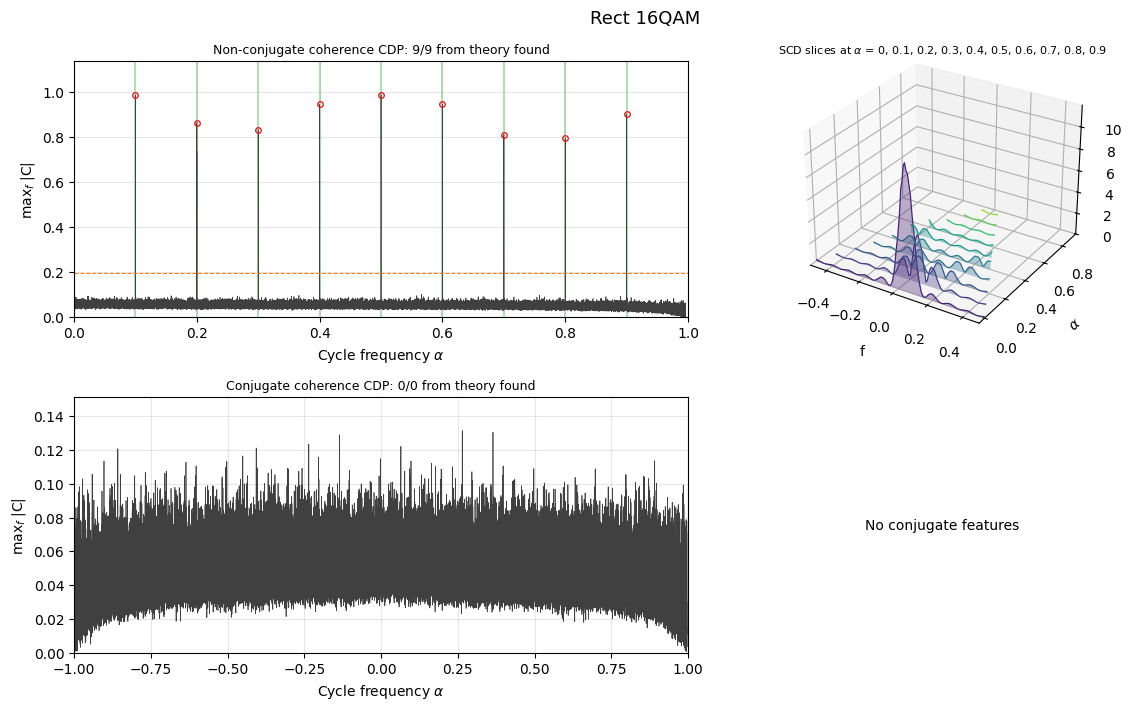

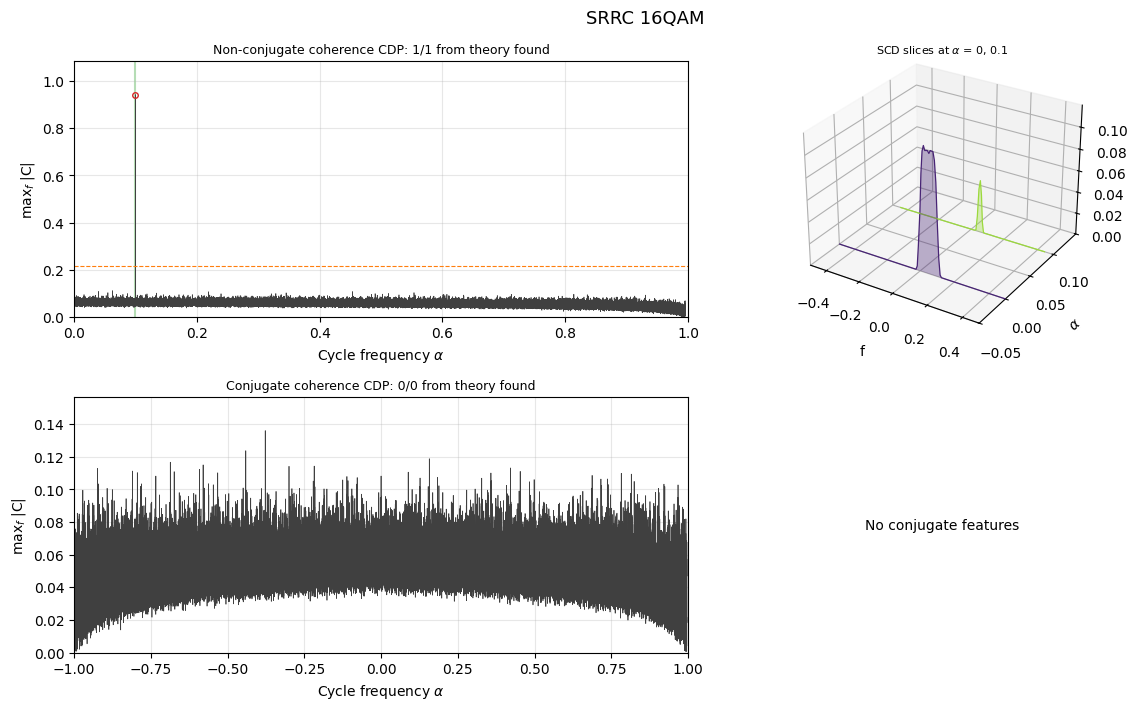

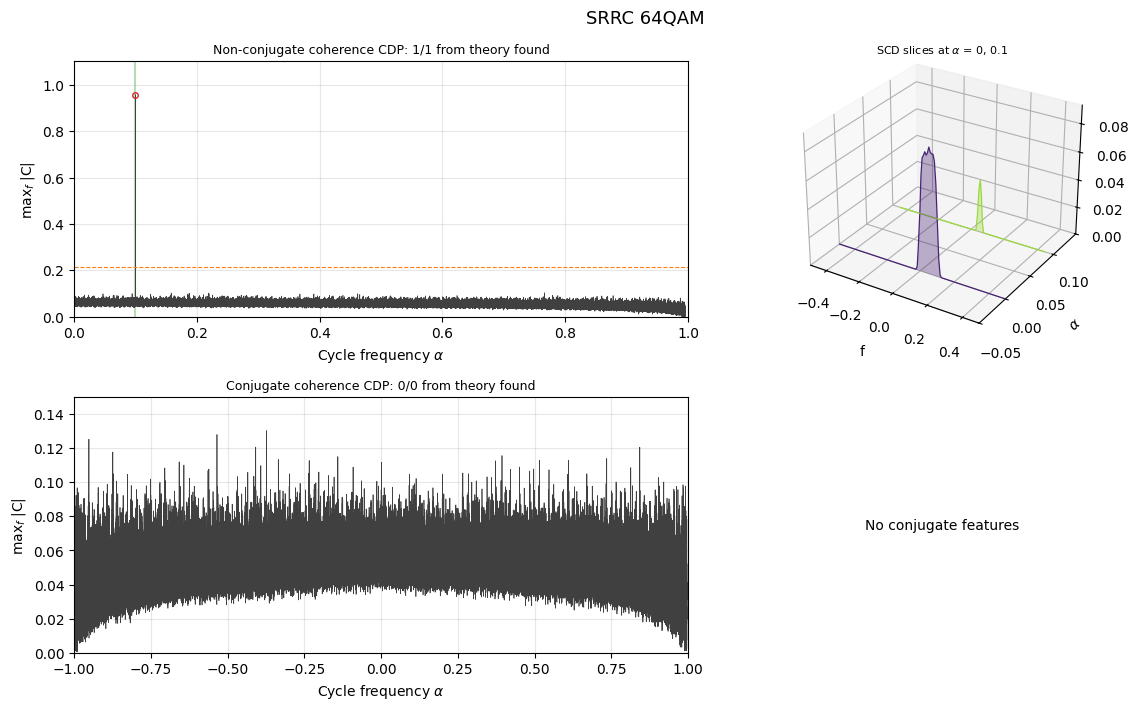

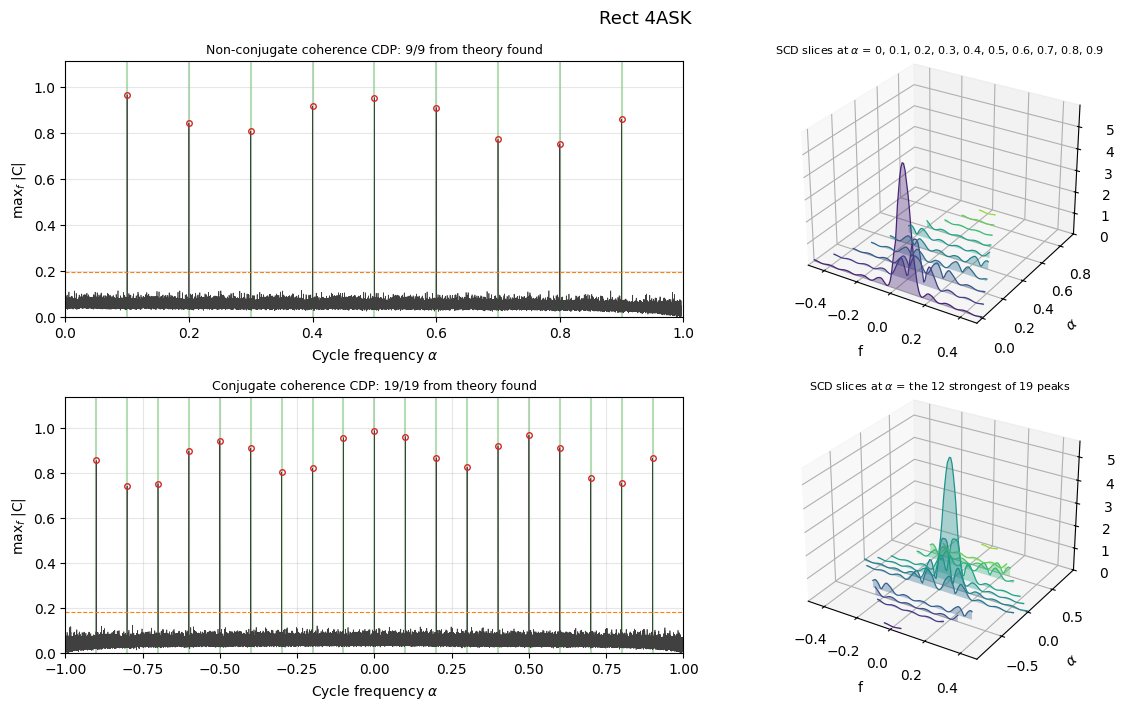

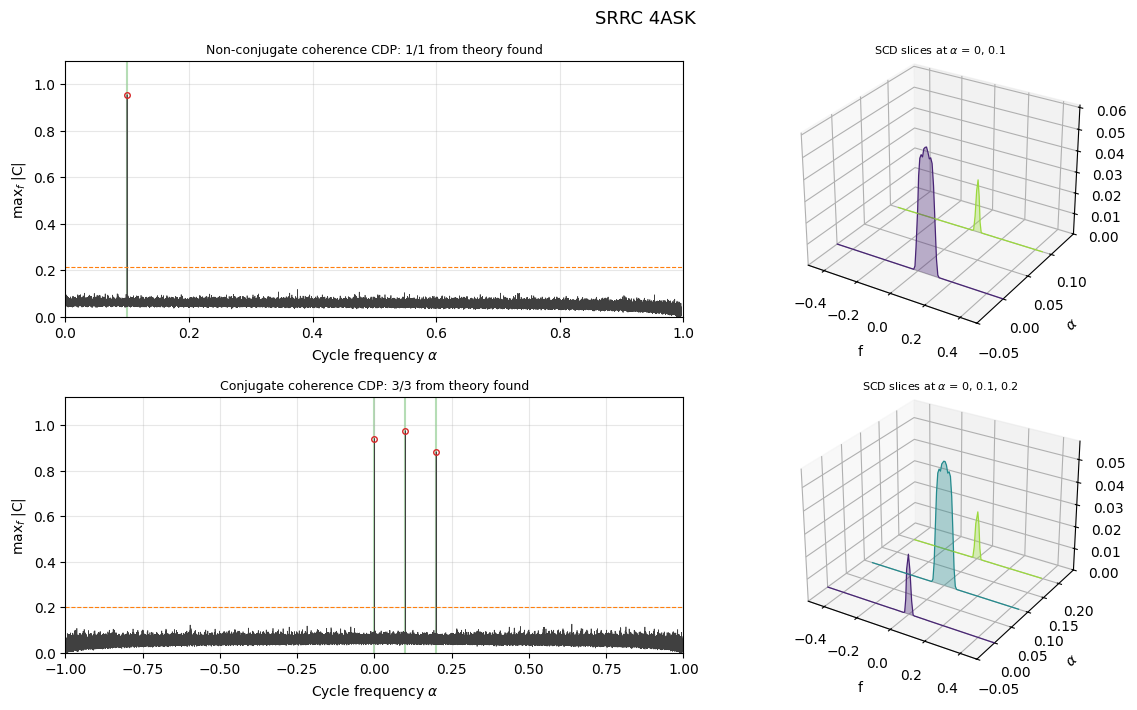

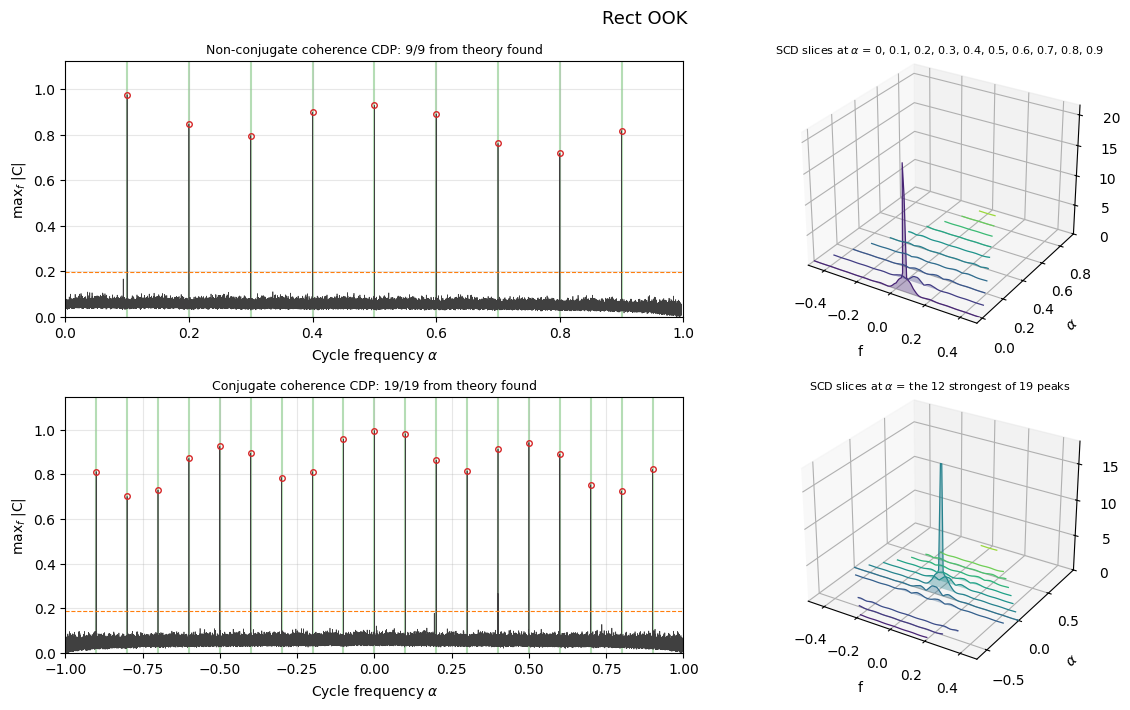

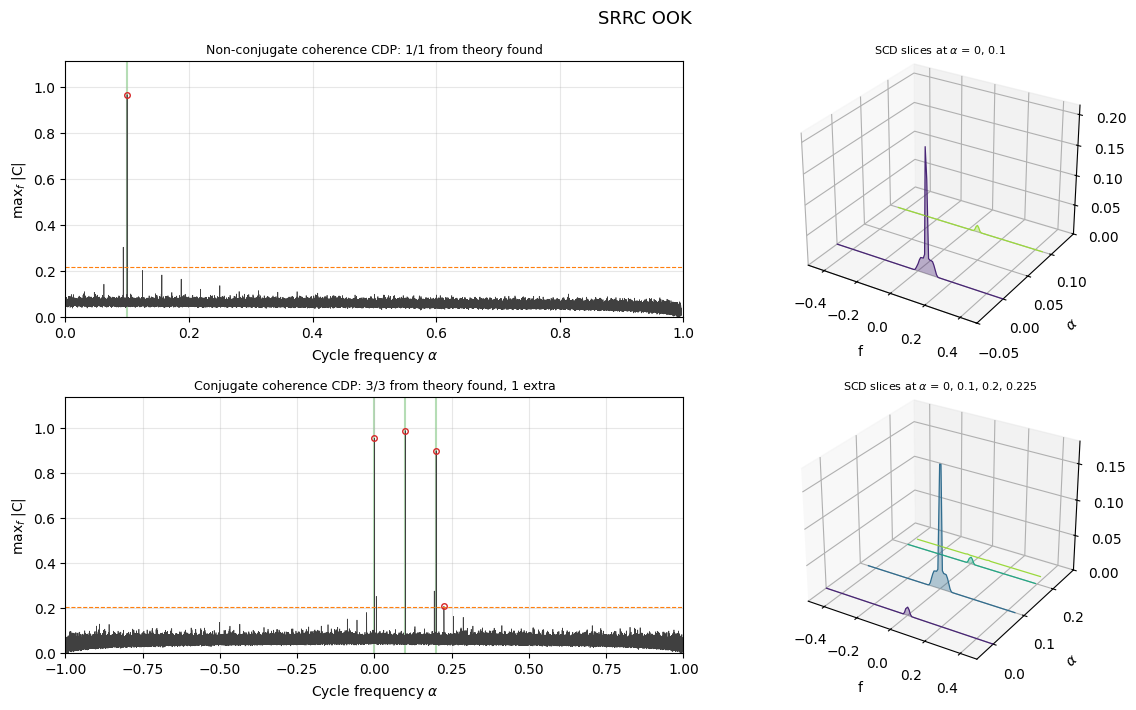

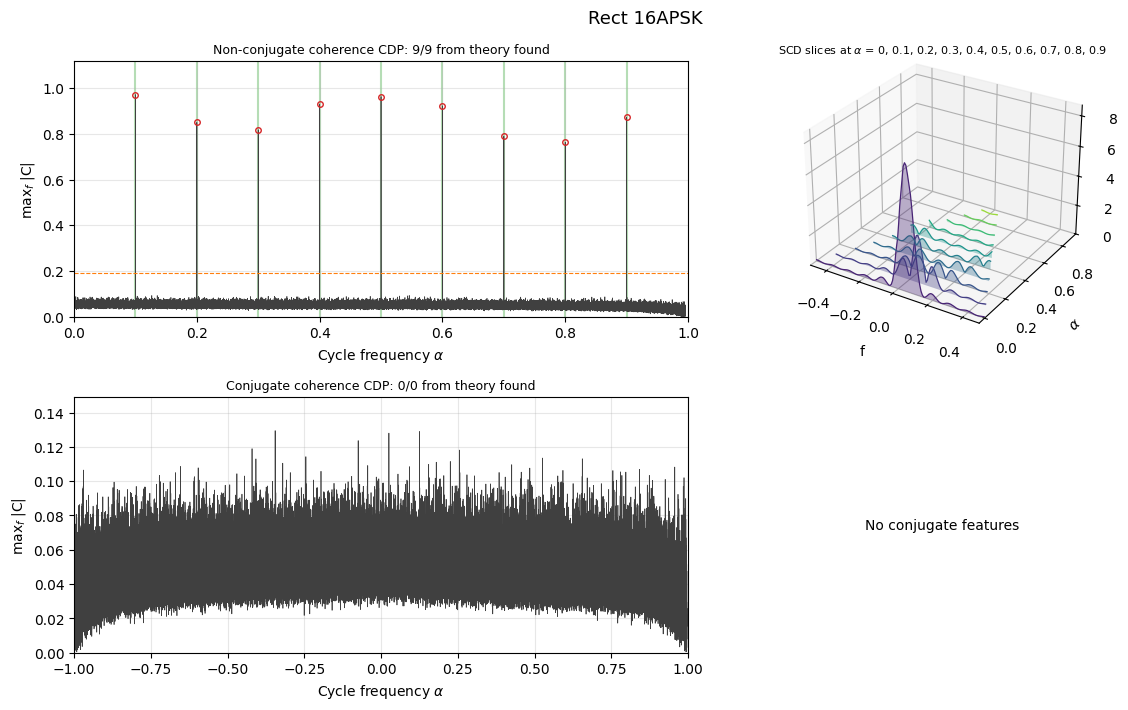

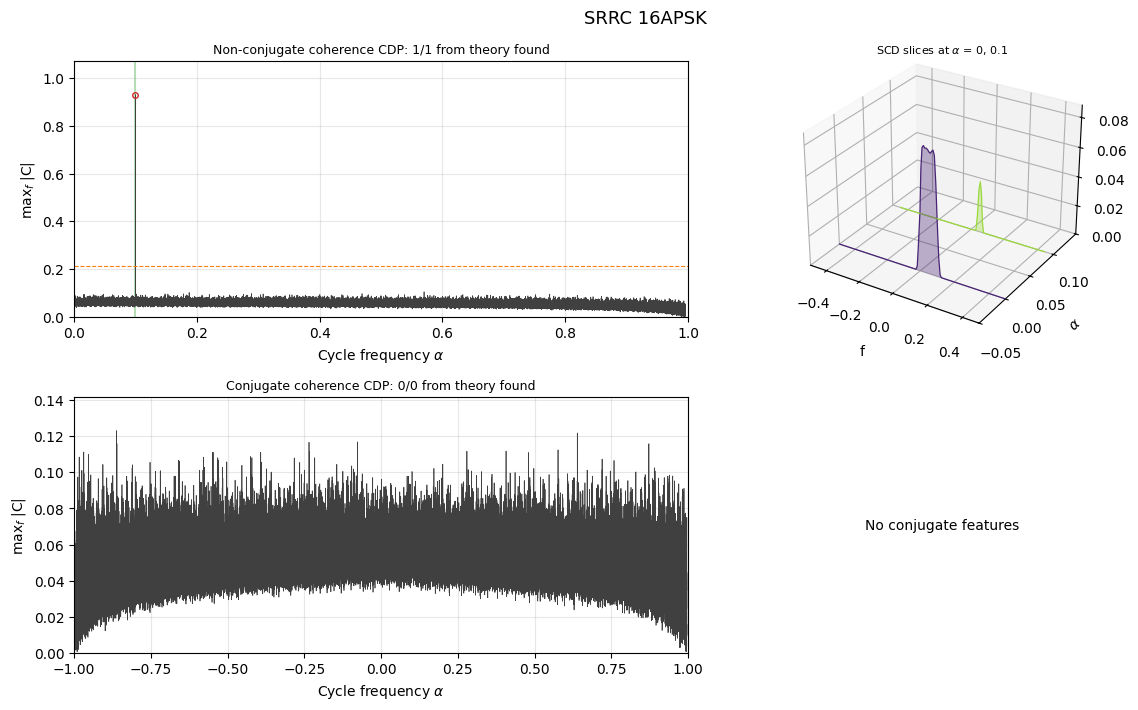

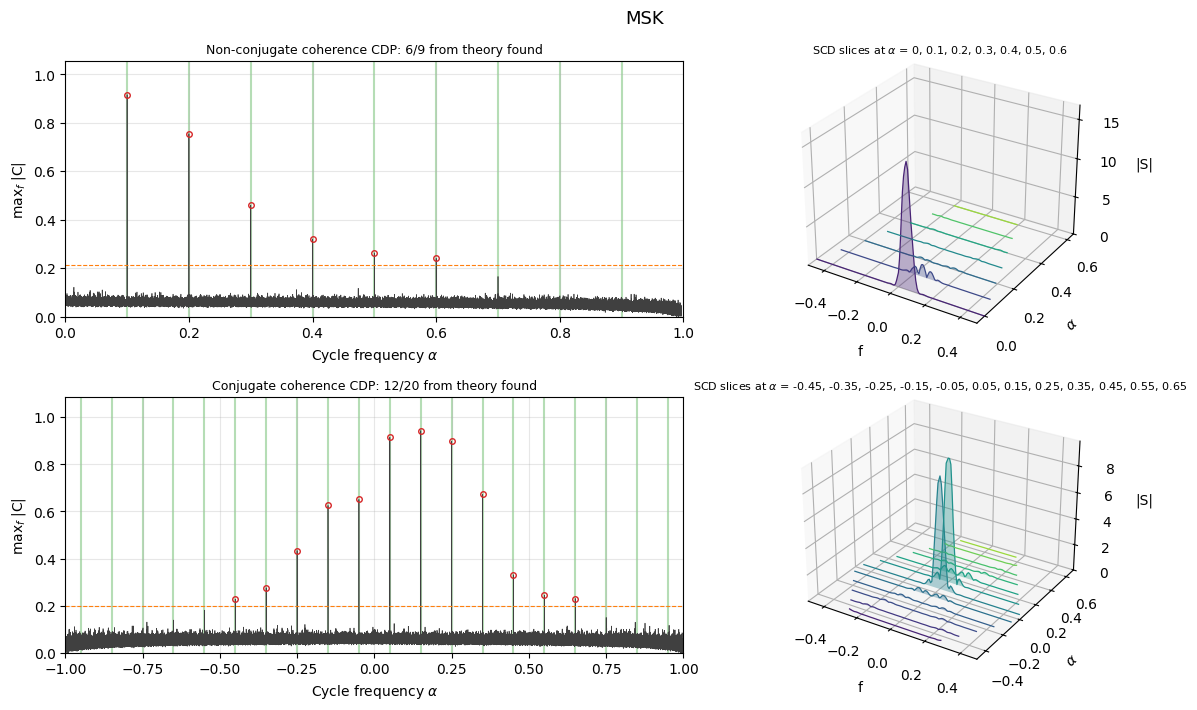

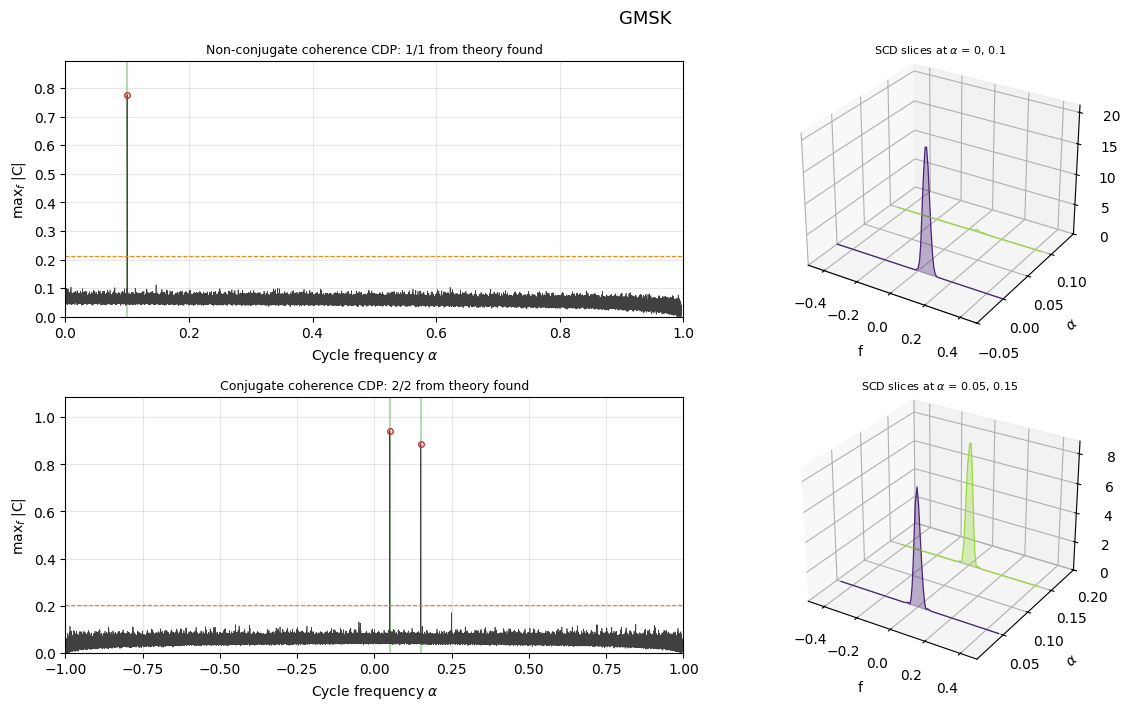

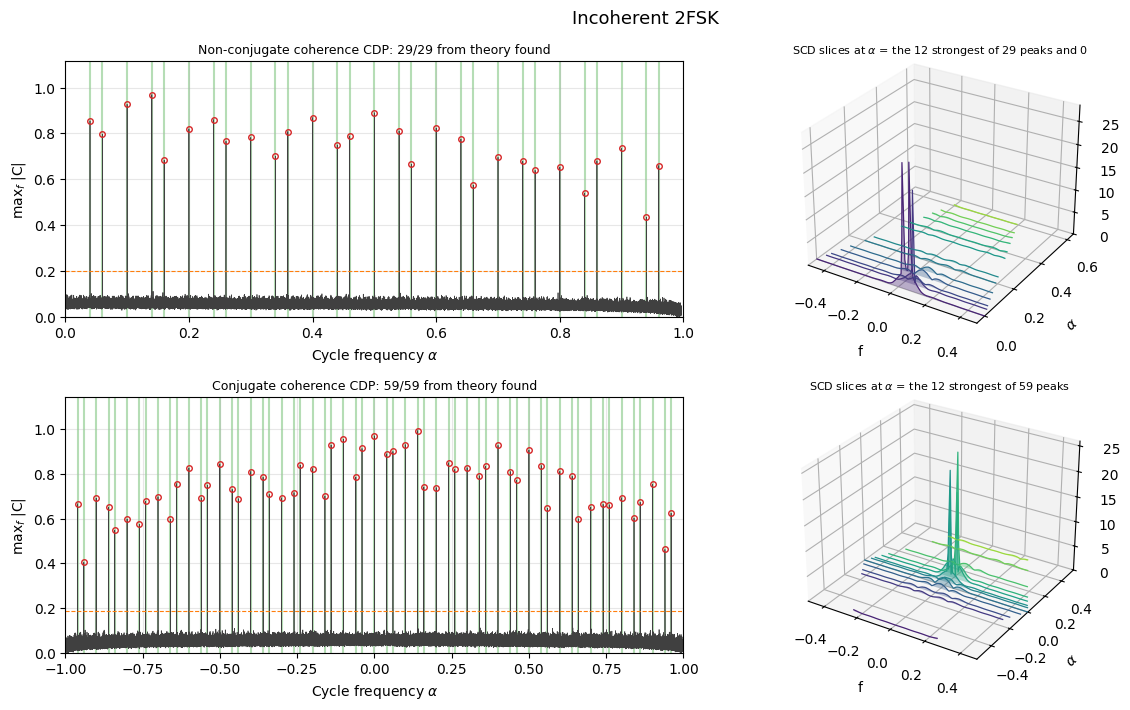

In [3]:
summaries = [show(name) for name in SIGNALS]

## Summary

The number of cycle frequencies from theory found for each signal. A **missing** cycle frequency is one in the
catalogue's list without a peak above the threshold. An **extra** peak is one above the threshold with no
cycle frequency from theory within `TOLERANCE`.

In [4]:
table = pd.DataFrame(summaries).set_index("signal")
pd.set_option("display.max_colwidth", 60)
table

,non-conjugate theory,non-conjugate found,non-conjugate missing,non-conjugate extra,conjugate theory,conjugate found,conjugate missing,conjugate extra
signal,,,,,,,,
Rect BPSK,9,9,,,19,19,,
SRRC BPSK,1,1,,,3,3,,
Rect QPSK,9,9,,,0,0,,
SRRC QPSK ($\beta$ = 0.1),1,1,,,0,0,,
Rect 8PSK,9,9,,,0,0,,
SRRC 8PSK,1,1,,,0,0,,
Rect $\pi$/4-DQPSK,9,9,,,0,0,,
SRRC $\pi$/4-DQPSK,1,1,,,0,0,,
Rect 16QAM,9,9,,,0,0,,


Every peak above the threshold is a cycle frequency from theory. The only misses are the higher harmonics
of MSK ($k f_{sym}$ for $k \geq 7$, and the outer conjugate features $2f_c + (2m + 1) f_{sym}/2$). Its spectrum
falls off as $1/f^4$, so these features weaken quickly. The lower ones still stand above the floor of the profile
but under the threshold. The weak GMSK features at $2f_c \pm 3f_{sym}/2$ are visible in the same way, but they are
not in the catalogue's list.